# Forecasting the Price of Crude Oil with Probabilistic Graphical Models
## Group Work Project 2: Methodology Description. Model Development
**MScFE 660 Risk Management, Group 18580**

This notebook carries out the nine steps of GWP2 on the data panel delivered in GWP1.
It is organised in the order of the assignment rather than the order of execution, and
every figure and number quoted in the report is produced here.

The panel is the sterilised monthly file from GWP1: 439 months from January 1990 to
July 2026 on 29 variables. Nothing is re-downloaded.

## Setup

`hmms` is a Cython package last released in 2017. It does not build against
NumPy 2, so `pip install hmms` fails on current Google Colab and on any recent
local Python. Two ways round it, in order of preference.

**Option A, no compiler needed.** This package ships `src/hmms_compat.py`, a pure
NumPy reimplementation of the four algorithms with the same call signatures. It
was checked against the Cython library on this panel: identical parameters give
identical forward and backward matrices and identical log likelihoods, and one
hundred Baum-Welch iterations from identical starting parameters reproduce A, B
and Pi exactly and the same Viterbi path on all 438 months. It also draws its random starting
parameters from the legacy global generator in the same order as the Cython library,
so `np.random.seed(k)` upstream fixes the same starting point either way. The cells
below fall back to it automatically.

**Option B, build the real library.** Patch the two NumPy names it uses and
compile, in one Colab cell:

```
!pip download hmms --no-deps --no-binary :all: -d /tmp/h -q
!cd /tmp/h && tar xzf hmms-*.tar.gz
!cd /tmp/h/hmms-*/ && sed -i 's/numpy\.int_t/numpy.int64_t/g; s/numpy\.int\b/numpy.int64/g' hmms/*.pyx \
    && pip install -q Cython && python setup.py build_ext --inplace \
    && cp -r hmms $(python -c "import site;print(site.getsitepackages()[0])")
```
**Dependencies.** Google Colab does not carry `pgmpy`. The next cell installs it at the
version this project was tested against and leaves it alone if it is already present.
Everything else the notebook needs, `numpy`, `pandas`, `matplotlib` and `networkx`, ships
with Colab and with any standard scientific Python install. `requirements.txt` in this
package lists the versions used for the figures and tables in the report.

**Working directory.** Run the notebook from the root of this package, so that `src/`
and `data_clean/` sit next to it. On Colab, clone the repository and `%cd` into it before running the cells below.


In [ ]:
# Dependencies. Installs only what is missing, so a rerun costs nothing.
import importlib.util, subprocess, sys

REQUIRED = {"pgmpy": "pgmpy==1.1.2", "networkx": "networkx", "matplotlib": "matplotlib"}
missing = [spec for mod, spec in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("installing:", ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
else:
    print("all dependencies already present")


In [ ]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")

HERE = os.path.abspath(".")
SRC = os.path.join(HERE, "src")
if SRC not in sys.path:
    sys.path.insert(0, SRC)

try:
    import hmms
    print("using hmms (Cython)")
except ImportError:
    import hmms_compat as hmms
    sys.modules["hmms"] = hmms
    print("hmms not installed; using hmms_compat (pure NumPy, numerically identical)")

using hmms (Cython)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import hmms
import pgmpy
import toy_hmm as toy
import gwp2_core as g
import pipeline_gwp2 as pl
import figures_gwp2 as fg
import viz

viz.apply_style()
print("numpy", np.__version__, "| pandas", pd.__version__, "| pgmpy", pgmpy.__version__)
print("HMM backend:", g.HMMS_BACKEND)

numpy 2.5.3 | pandas 3.0.5 | pgmpy 1.1.2
HMM backend: hmms (Cython)


# Step 1. The four hidden Markov model algorithms

One worked example runs through all three parts: two regimes, two symbols, three
months. Small enough to check by hand, which is the point. The pseudocode for each
algorithm is in the report; here it is implemented and cross-checked against `hmms`.

| Parameter | Value |
|---|---|
| States | Bull, Bear |
| Symbols | 0 = fall, 1 = rise |
| Pi | Bull 0.6, Bear 0.4 |
| A | Bull to Bull 0.7, Bear to Bull 0.4 |
| B | Bull emits up 0.8, Bear emits up 0.3 |
| O | (up, down, up) |

In [ ]:
print("Pi =", toy.PI)
print("A  =\n", toy.A)
print("B  =\n", toy.B)
print("O  =", [toy.SYMBOLS[o] for o in toy.O])

Pi = [0.6 0.4]
A  =
 [[0.7 0.3]
 [0.4 0.6]]
B  =
 [[0.2 0.8]
 [0.7 0.3]]
O  = ['up', 'down', 'up']


## Step 1a. Forward and backward

Both recursions return P(O | lambda) from opposite ends. The product
alpha_t(i) beta_t(i), summed over i, must be constant in t. That identity is the
cheapest test of a correct implementation.

In [ ]:
alpha = toy.forward(toy.PI, toy.A, toy.B, toy.O)
beta  = toy.backward(toy.A, toy.B, toy.O)

tbl = pd.DataFrame({
    "o_t": [toy.SYMBOLS[o] for o in toy.O],
    "alpha Bull": alpha[:, 0], "alpha Bear": alpha[:, 1],
    "beta Bull":  beta[:, 0],  "beta Bear":  beta[:, 1],
}, index=[1, 2, 3])
tbl.index.name = "t"
display(tbl.round(6))

p_fwd = alpha[-1].sum()
p_bwd = (toy.PI * toy.B[:, toy.O[0]] * beta[0]).sum()
print(f"P(O|lambda) forward  = {p_fwd:.6f}")
print(f"P(O|lambda) backward = {p_bwd:.6f}")
print("alpha_t . beta_t at each t =", [round(float((alpha[t]*beta[t]).sum()), 6)
                                       for t in range(len(toy.O))])

,o_t,alpha Bull,alpha Bear,beta Bull,beta Bear
t,,,,,
1,up,0.480000,0.120000,0.196,0.262
2,down,0.076800,0.151200,0.650,0.500
3,up,0.091392,0.034128,1.000,1.000


P(O|lambda) forward  = 0.125520
P(O|lambda) backward = 0.125520
alpha_t . beta_t at each t = [0.12552, 0.12552, 0.12552]


In [ ]:
# cross-check against the library the course mandates
m = hmms.DtHMM(toy.A, toy.B, toy.PI)
O64 = toy.O.astype(np.int64)
print("hmms alpha\n", np.exp(m.forward(O64)).round(6))
print("hmms P(O|lambda) =", round(float(np.exp(m.emission_estimate(O64))), 6))

hmms alpha
 [[0.48     0.12    ]
 [0.0768   0.1512  ]
 [0.091392 0.034128]]
hmms P(O|lambda) = 0.12552


**Answer.** Forward and backward agree at 0.125520, and the alpha-beta product is
constant across the three dates. The `hmms` implementation returns the same alpha
matrix to six decimals. The forward recursion costs O(T N^2) against O(N^T) for
enumerating paths, because every history ending in a given state is collapsed into one
number before being extended.

## Step 1b. Viterbi, and its backward pass

Viterbi is the forward recursion with the sum replaced by a maximum, plus the pointer
array psi. The backward pass recomputes nothing: it walks psi from the terminal
argmax back to t = 1.

In [ ]:
delta, psi, path = toy.viterbi(toy.PI, toy.A, toy.B, toy.O)
vt = pd.DataFrame({
    "o_t": [toy.SYMBOLS[o] for o in toy.O],
    "delta Bull": delta[:, 0], "delta Bear": delta[:, 1],
    "psi Bull": ["-"] + [toy.STATES[i] for i in psi[1:, 0]],
    "psi Bear": ["-"] + [toy.STATES[i] for i in psi[1:, 1]],
}, index=[1, 2, 3])
vt.index.name = "t"
display(vt.round(6))

print("decoded path :", [toy.STATES[i] for i in path])
print(f"probability  : {delta[-1].max():.6f}   log probability: {np.log(delta[-1].max()):.6f}")

lp, hp = m.viterbi(O64)
print("hmms path    :", [toy.STATES[i] for i in np.asarray(hp)], " log prob", round(float(lp), 6))

,o_t,delta Bull,delta Bear,psi Bull,psi Bear
t,,,,,
1,up,0.480000,0.120000,-,-
2,down,0.067200,0.100800,Bull,Bull
3,up,0.037632,0.018144,Bull,Bear


decoded path : ['Bull', 'Bull', 'Bull']
probability  : 0.037632   log probability: -3.279901
hmms path    : ['Bull', 'Bull', 'Bull']  log prob -3.279901


In [ ]:
# the most likely state at each date is not the most likely sequence
gamma, xi, pi_new, A_new, B_new, p_O = toy.baum_welch_step(toy.PI, toy.A, toy.B, toy.O)
print("argmax of the posterior marginal :", [toy.STATES[i] for i in gamma.argmax(1)])
print("Viterbi path                     :", [toy.STATES[i] for i in path])

argmax of the posterior marginal : ['Bull', 'Bear', 'Bull']
Viterbi path                     : ['Bull', 'Bull', 'Bull']


**Answer.** Viterbi returns Bull, Bull, Bull with probability 0.037632. Taking the
largest posterior marginal at each date returns Bull, Bear, Bull. The two disagree on a
three-month sequence because they answer different questions: the marginal maximises the
expected count of correctly labelled months, Viterbi maximises the probability of the
whole path being right. A downstream model that consumes a sequence, as the belief
network does, needs the Viterbi object.

At our sample length delta underflows, so a production implementation works in
logarithms. `hmms` returns a log probability for that reason.

## Step 1c. Baum-Welch

Expectation-maximisation for a hidden chain. gamma is the expected occupancy of a state
at a date, xi the expected count of a transition. The M step is a ratio of expected
counts to expected totals.

In [ ]:
display(pd.DataFrame(gamma, columns=toy.STATES, index=[1, 2, 3]).rename_axis("t").round(6))
print("expected transition counts, summed over t")
display(pd.DataFrame(xi.sum(0), index=toy.STATES, columns=toy.STATES).round(6))

before_after = pd.DataFrame({
    "before": [toy.PI[0], toy.A[0, 0], toy.A[1, 0], toy.B[0, 1], toy.B[1, 1]],
    "after one iteration": [pi_new[0], A_new[0, 0], A_new[1, 0], B_new[0, 1], B_new[1, 1]],
}, index=["Pi Bull", "A Bull->Bull", "A Bear->Bull", "B Bull emits up", "B Bear emits up"])
display(before_after.round(6))

print(f"P(O|lambda) before = {p_O:.6f}")
print(f"P(O|lambda) after  = {toy.forward(pi_new, A_new, B_new, toy.O)[-1].sum():.6f}")

,Bull,Bear
t,,
1,0.749522,0.250478
2,0.397706,0.602294
3,0.728107,0.271893


expected transition counts, summed over t


,Bull,Bear
Bull,0.690631,0.456597
Bear,0.435182,0.417591


,before,after one iteration
Pi Bull,0.6,0.749522
A Bull->Bull,0.7,0.602000
A Bear->Bull,0.4,0.510314
B Bull emits up,0.8,0.787928
B Bear emits up,0.3,0.464468


P(O|lambda) before = 0.125520
P(O|lambda) after  = 0.156449


**Answer.** One iteration raises the likelihood from 0.125520 to 0.156449. The
increase is monotone by construction; convergence to the global maximum is not
guaranteed, which is why the random initialisation matters and why our runs fix a seed.

Two consequences for the panel. The surface has many local optima, so a single run from
one random start, which is what the dissertation does, is not reproducible unless the
seed is recorded. And with two symbols against three states the model has more states
than the alphabet can distinguish, so at least one state is identified by the transition
structure alone. Step 2 shows what that produces.

# Step 3. Definition 3 restated

A discrete hidden Markov model is an index structure plus a parameter set.

The index structure is a state space Q = {s_1 ... s_N} and an emission alphabet
V = {v_1 ... v_M}, both chosen by the modeller. The parameters are
lambda = (Pi, A, B) with a_ij = P(q_t+1 = s_j | q_t = s_i) and
b_i(k) = P(o_t = v_k | q_t = s_i). Pi and every row of A and B sum to one.

The model asserts two conditional independences, and they are its content:

- Markov property on the chain, P(q_t+1 | q_t ... q_1) = P(q_t+1 | q_t)
- output independence, P(o_t | q_t ... q_1, o_t-1 ... o_1) = P(o_t | q_t)

Together they give the joint factorisation over a path and a sequence, and with it the
validity of all four algorithms above.

Two changes against the statement in the dissertation. It writes the alphabet as M
symbols while indexing it to N, so one letter counts two things; we separate them,
which matters because our model runs three states against two symbols. And it lists the
three normalisation constraints without ever writing the independences, yet those
constraints only say that Pi, A and B are distributions. They would hold for a model
that let the emission depend on the previous observation, which would not be a hidden
Markov model at all.

Reference: Bishop, *Pattern Recognition and Machine Learning*, 2006, section 13.2, with
Murphy, *Machine Learning: A Probabilistic Perspective*, 2012, chapter 17.

# Steps 4 and 6. The design of Figure 3.1, carried out

Figure 3.1 of the dissertation is a loop: macro research, identify indicators, retrieve
datasets, clean the data with pandas, identify the regime with `hmms`, train the network
with `pgmpy`, check the validation error, change parameters if it is too high, otherwise
test. The first four boxes were delivered in GWP1. This section runs the rest.

## Node selection

Three variables are removed before any structure search, on the collinearity evidence
of GWP1 section 5.4. Leaving them in spends edges on identities.

In [ ]:
monthly = g.load_monthly()
print(f"GWP1 panel: {monthly.shape[0]} months x {monthly.shape[1]} columns")

for k, why in g.TAUTOLOGIES.items():
    print(f"  dropped {k:14s} {why}")
print()
for k, start in g.LATE_START.items():
    print(f"  held out {k:10s} first observed {start}, keeping the 1990 window intact")

nodes = pl.model_nodes()
panel = monthly[nodes]
print(f"\nmodel panel: {panel.shape[0]} months x {panel.shape[1]} variables")
print(nodes)

GWP1 panel: 439 months x 29 columns
  dropped PPI_CRUDE      producer price index for crude petroleum, measures the target rather than driving it
  dropped CAPUTL_OILGAS  capacity utilisation is output divided by capacity, already carried by IP_OILGAS and CAP_OILGAS
  dropped BRENT_M        second light sweet benchmark, co-moves with WTI by construction

  held out USD_M      first observed 2006-01, keeping the 1990 window intact
  held out GEPU       first observed 1997-01, keeping the 1990 window intact
  held out HH_GAS_M   first observed 1997-01, keeping the 1990 window intact
  held out GAS_EU     first observed 1992-01, keeping the 1990 window intact

model panel: 439 months x 17 variables
['CPIENG', 'FEDFUNDS', 'GS10', 'IGREA', 'INDPRO', 'M2', 'UNRATE', 'USEPU', 'GEOEVENT', 'CAP_OILGAS', 'IP_DRILL', 'IP_OILGAS', 'PPI_DRILL', 'PPI_OILGAS', 'GOLD', 'SP500', 'WTI_M']


In [ ]:
# the correlation of monthly changes that motivates the three removals
d = monthly[["WTI_M", "BRENT_M", "PPI_CRUDE", "IP_OILGAS", "CAPUTL_OILGAS"]].diff()
display(d.corr().round(3))

,WTI_M,BRENT_M,PPI_CRUDE,IP_OILGAS,CAPUTL_OILGAS
WTI_M,1.000,0.944,0.944,-0.030,-0.025
BRENT_M,0.944,1.000,0.887,-0.018,-0.011
PPI_CRUDE,0.944,0.887,1.000,0.008,0.005
IP_OILGAS,-0.030,-0.018,0.008,1.000,0.925
CAPUTL_OILGAS,-0.025,-0.011,0.005,0.925,1.000


## Step 6a. Transforming the time series

The emission sequence is the parity of the first difference: 1 for a rise, 0 for a
fall. One observation is lost at the start.

first 24 months of the WTI emission sequence
[0 0 0 0 0 1 1 1 1 0 0 0 0 0 1 1 0 1 1 1 1 0 0 0]


,share of months encoded as a rise
GEOEVENT,0.034
UNRATE,0.317
FEDFUNDS,0.434
GS10,0.438
USEPU,0.468
GOLD,0.495
IGREA,0.518
PPI_OILGAS,0.539
CPIENG,0.543
CAP_OILGAS,0.566


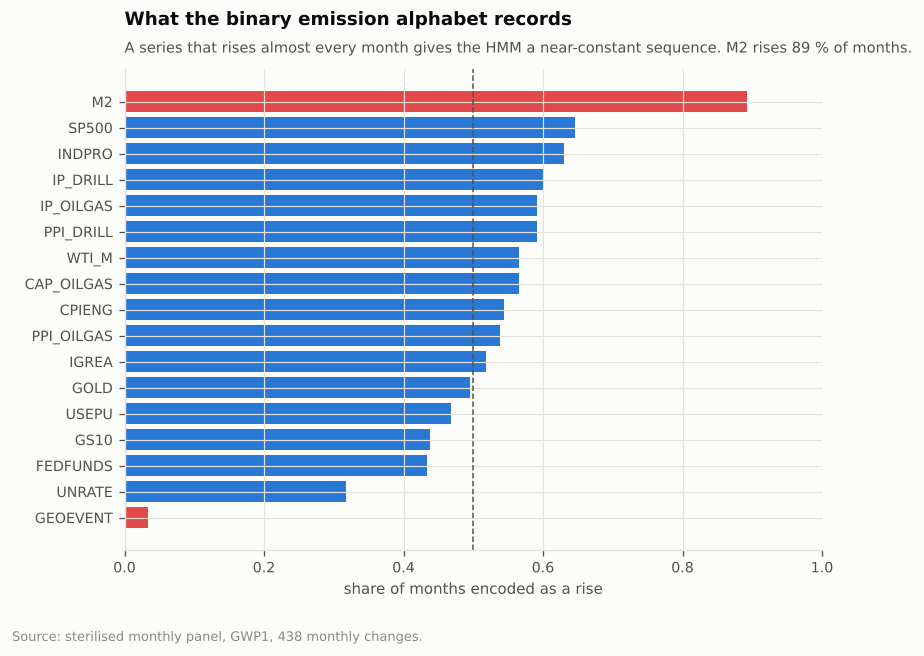

In [ ]:
emis = g.emission_sequence(monthly["WTI_M"])
print("first 24 months of the WTI emission sequence")
print(emis.head(24).values)

shares_up = (panel.diff().iloc[1:] > 0).mean().sort_values()
display(shares_up.round(3).to_frame("share of months encoded as a rise"))
fg.fig_emission_balance(shares_up); plt.show()

**Answer.** The encoding is lossy in a way that matters. A month up 0.2 per cent and a
month up 18 per cent are the same symbol, so the alphabet records direction and discards
size. For a trending series the sequence is close to constant: M2 rises in 89.3 per cent
of months, which leaves the chain almost nothing to separate. WTI itself is balanced at
56.6 per cent, which is why the regime fit on the target is the usable one.

## Step 6b. Learning the parameters

Baum-Welch is treated as a black box here, as the assignment allows; the mechanics are
in Step 1c. One HMM per variable, three states, two symbols, 100 iterations, fitted on
the training window only. The validation and test windows are never seen by the
estimator.

In [ ]:
train_idx, valid_idx, test_idx = g.split_index(panel.index)
print(f"train {train_idx.min():%Y-%m} to {train_idx.max():%Y-%m}  ({len(train_idx)} months)")
print(f"valid {valid_idx.min():%Y-%m} to {valid_idx.max():%Y-%m}  ({len(valid_idx)} months)")
print(f"test  {test_idx.min():%Y-%m} to {test_idx.max():%Y-%m}  ({len(test_idx)} months)")

wti_hmm = g.fit_hmm(g.emission_sequence(monthly["WTI_M"].loc[train_idx]), seed=0)
print("\nfitted HMM for WTI")
print("Pi\n", wti_hmm.pi.round(4))
print("A\n", wti_hmm.a.round(4))
print("B\n", wti_hmm.b.round(4))

train 1990-01 to 2019-03  (351 months)
valid 2019-04 to 2022-11  (44 months)
test  2022-12 to 2026-07  (44 months)



fitted HMM for WTI
Pi
 [6.772e-01 1.000e-04 3.227e-01]
A
 [[0.3484 0.3787 0.2729]
 [0.5234 0.458  0.0186]
 [0.0411 0.4648 0.4941]]
B
 [[0.0236 0.9764]
 [0.4946 0.5054]
 [0.9209 0.0791]]


## Step 6c. Decoding the most likely sequence

Viterbi returns the path. Then the three raw labels are ranked by the mean monthly
change they carry, which is what turns an arbitrary state index into bear, stagnant or
bull.

One property of the algorithm decides how the output may be used. Viterbi maximises
over the whole sequence, so the label it gives month t is informed by months after t.
That is a smoothing operation. It is the right tool for describing history and the wrong
one for forecasting, so the pipeline is run twice: once smoothed, as the dissertation
specifies, and once with decoding restricted to information available at t.

  0%|          | 0/44 [00:00<?, ?it/s]

 55%|█████▍    | 24/44 [00:00<00:00, 233.74it/s]

100%|██████████| 44/44 [00:00<00:00, 221.15it/s]

  0%|          | 0/44 [00:00<?, ?it/s]

 55%|█████▍    | 24/44 [00:00<00:00, 237.29it/s]

100%|██████████| 44/44 [00:00<00:00, 228.41it/s]

... (3 outputs left out)

  0%|          | 0/42 [00:00<?, ?it/s]

 57%|█████▋    | 24/42 [00:00<00:00, 224.39it/s]

100%|██████████| 42/42 [00:00<00:00, 218.64it/s]

panel 439 months x 17 variables
train 351 | valid 44 | test 44
mean agreement smoothed vs causal: 0.855
lisse   edges=18 blanket=['CPIENG', 'INDPRO', 'PPI_OILGAS', 'WTI_M'] valid=0.705 test=0.727
causal  edges=16 blanket=['WTI_M'] valid=0.585 test=0.452
figures: G1_regime_path.png, G2_emission_balance.png, G3_regime_shares.png, G4_transition_matrix.png, G5_decoding_gap.png, G6_accuracy.png, G7_network.png


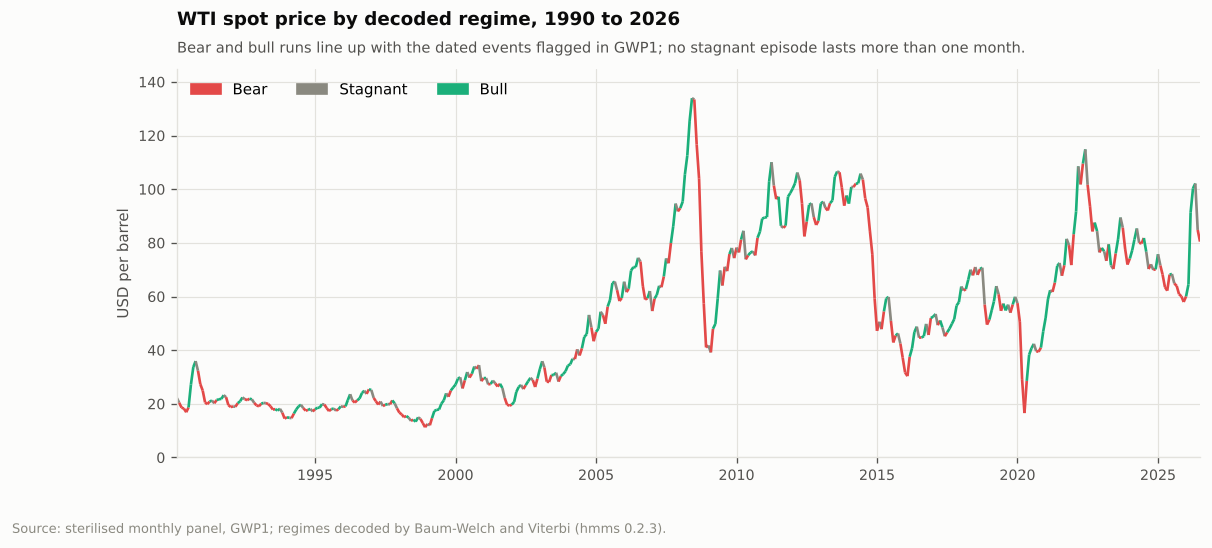

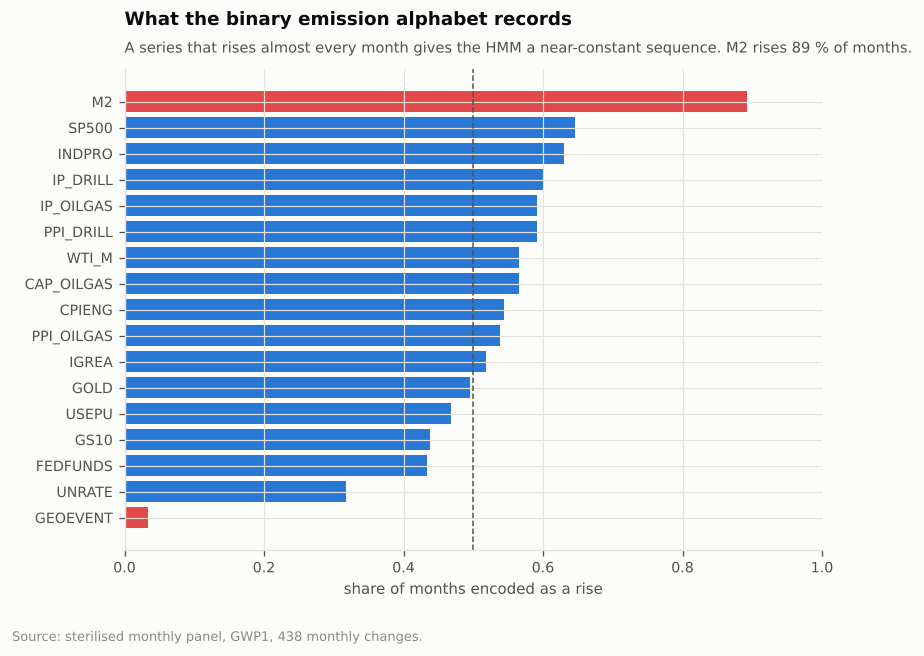

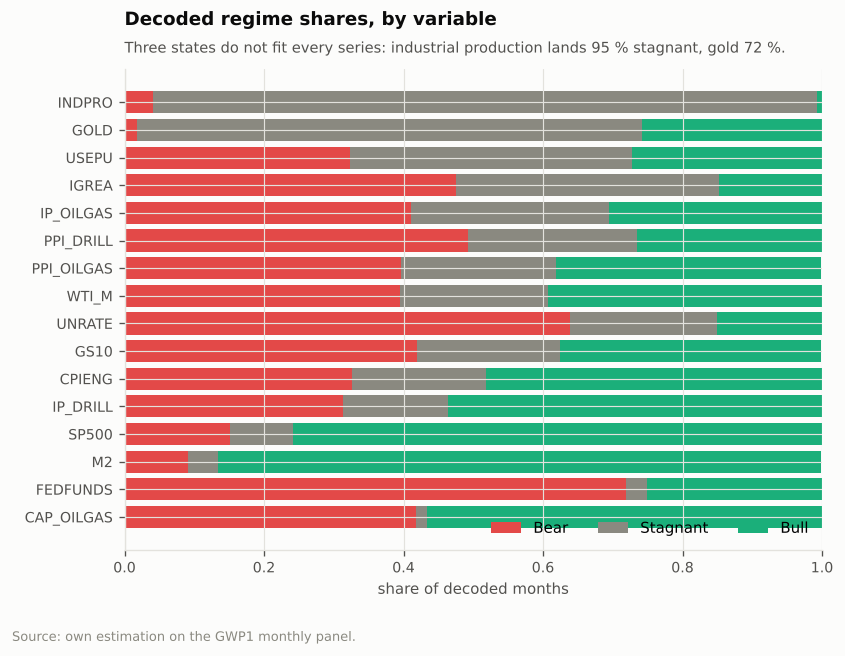

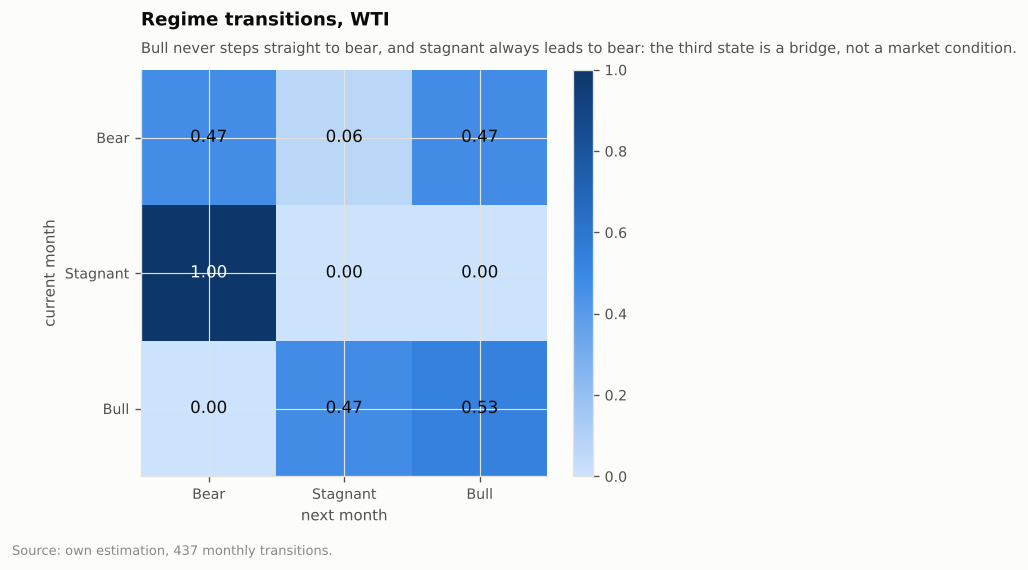

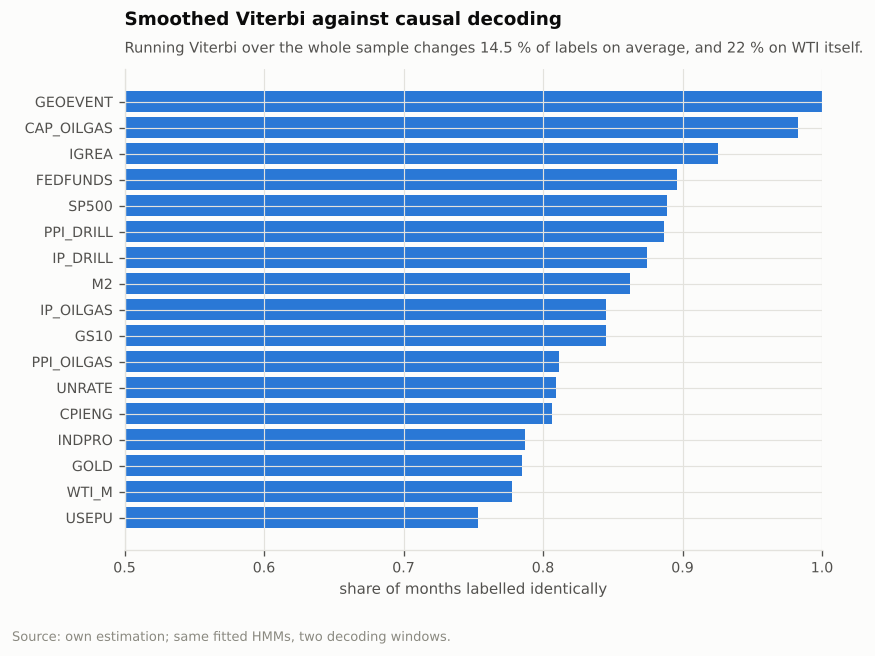

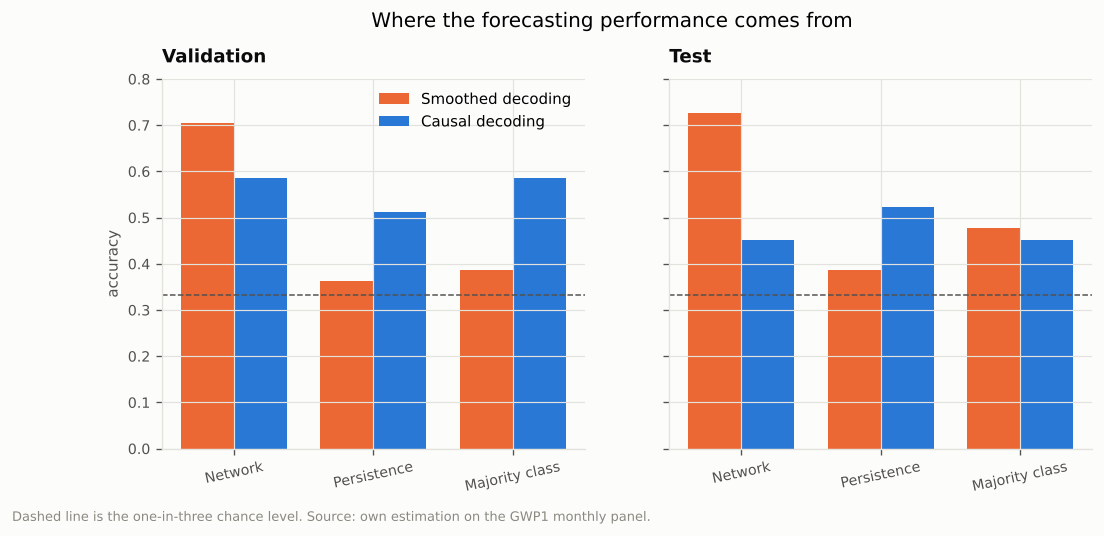

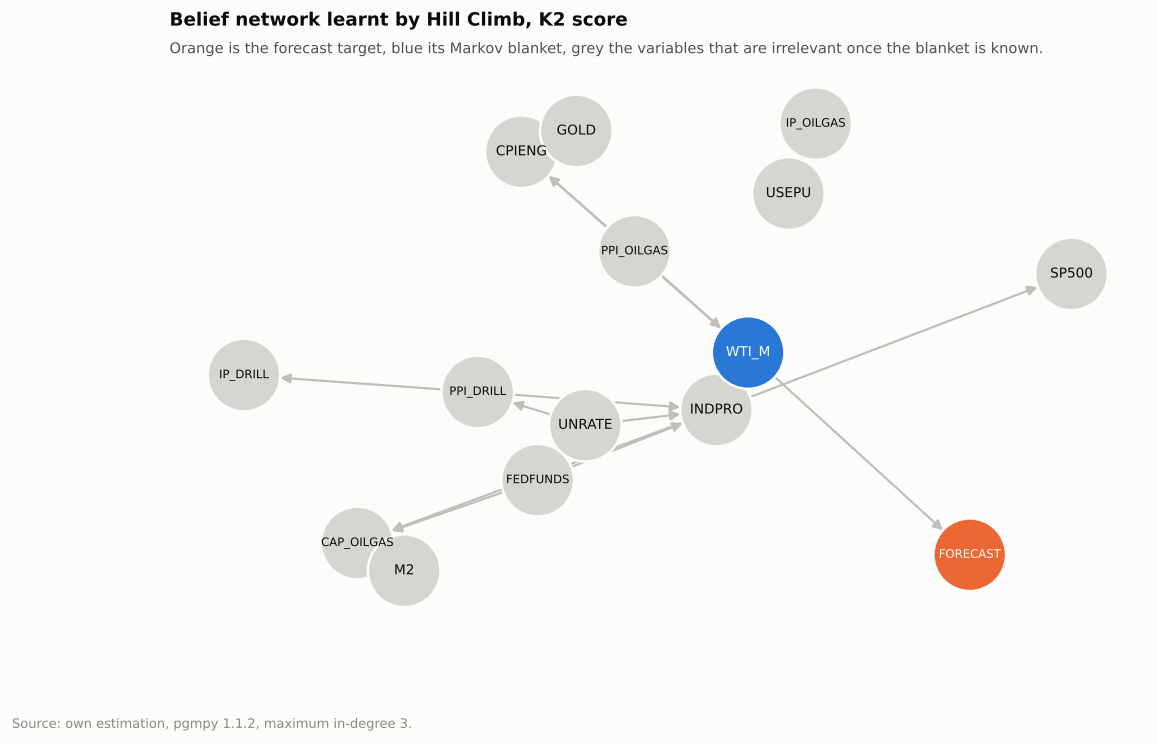

In [ ]:
summary, disc_s, disc_c, diag, episodes, tm, models = pl.run()

In [ ]:
print("HMM fit diagnostics, by variable")
display(diag)

HMM fit diagnostics, by variable


,variable,status,n,share_bear,share_stagnant,share_bull,persistence
0,CPIENG,ok,438,0.326,0.192,0.482,0.369
1,FEDFUNDS,ok,438,0.719,0.030,0.251,0.651
2,GS10,ok,438,0.420,0.205,0.374,0.316
3,IGREA,ok,438,0.475,0.377,0.148,0.435
4,INDPRO,ok,438,0.041,0.952,0.007,0.696
5,M2,ok,438,0.091,0.043,0.865,0.585
6,UNRATE,ok,438,0.639,0.210,0.151,0.379
7,USEPU,ok,438,0.324,0.404,0.272,0.218
8,CAP_OILGAS,ok,438,0.418,0.016,0.566,0.595
9,IP_DRILL,ok,438,0.313,0.151,0.537,0.488


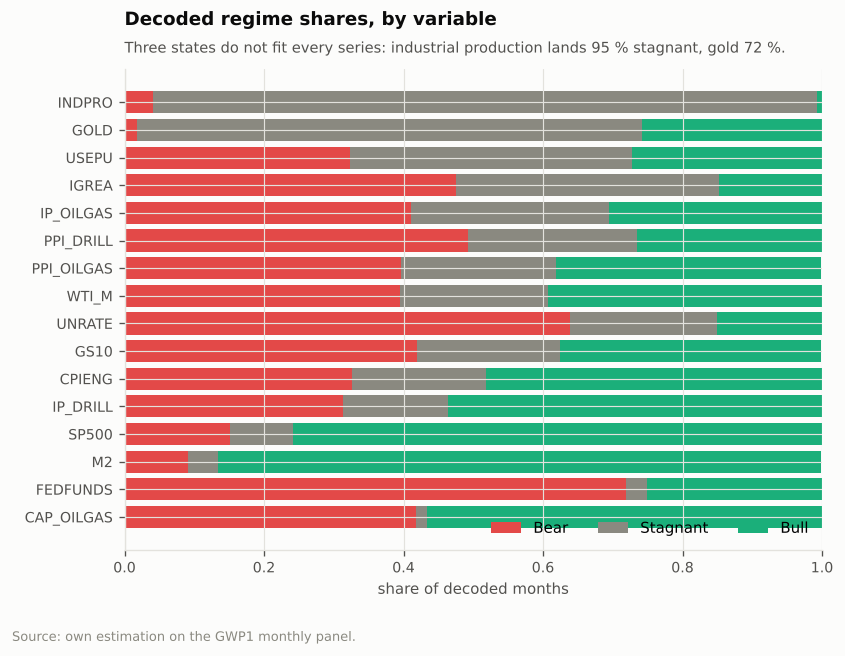

In [ ]:
fg.fig_regime_shares(diag); plt.show()

# Step 2. Bull, bear and stagnant regimes

The decoded path for WTI, and the episodes it contains.

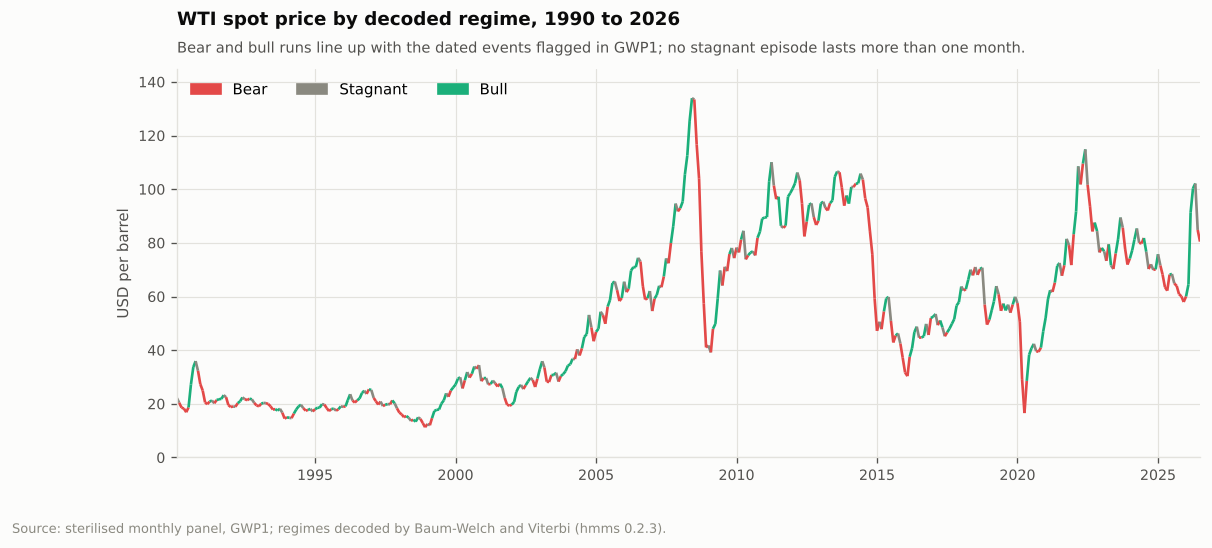

In [ ]:
fg.fig_regime_path(monthly["WTI_M"], disc_s["WTI_M"]); plt.show()

In [ ]:
print("longest episodes of each regime")
for rg in ["bull", "bear", "stagnant"]:
    sub = episodes[episodes.regime == rg].nlargest(3, "months")
    display(sub[["start", "end", "months", "wti_start", "wti_end", "move_pct"]]
            .assign(regime=rg).reset_index(drop=True))

print("mean duration in months")
display(episodes.groupby("regime")["months"].agg(["size", "mean", "max"]).round(2))

longest episodes of each regime


,start,end,months,wti_start,wti_end,move_pct,regime
0,1999-03-01,1999-08-01,6,14.66,21.26,45.0,bull
1,2010-10-01,2011-03-01,6,81.90,102.94,25.7,bull
2,2017-07-01,2017-12-01,6,46.63,57.88,24.1,bull


,start,end,months,wti_start,wti_end,move_pct,regime
0,2014-07-01,2015-01-01,7,103.59,47.22,-54.4,bear
1,2008-07-01,2008-12-01,6,133.44,41.02,-69.3,bear
2,1990-11-01,1991-03-01,5,32.30,19.86,-38.5,bear


,start,end,months,wti_start,wti_end,move_pct,regime
0,1990-02-01,1990-02-01,1,22.11,22.11,0.0,stagnant
1,1990-10-01,1990-10-01,1,35.92,35.92,0.0,stagnant
2,1991-05-01,1991-05-01,1,21.24,21.24,0.0,stagnant


mean duration in months


,size,mean,max
regime,,,
bear,93,1.86,7
bull,81,2.12,6
stagnant,93,1.00,1


empirical transition matrix, rows are the current month


,Bear,Stagnant,Bull
Bear,0.465116,0.063953,0.47093
Stagnant,1.000000,0.000000,0.00000
Bull,0.000000,0.470930,0.52907


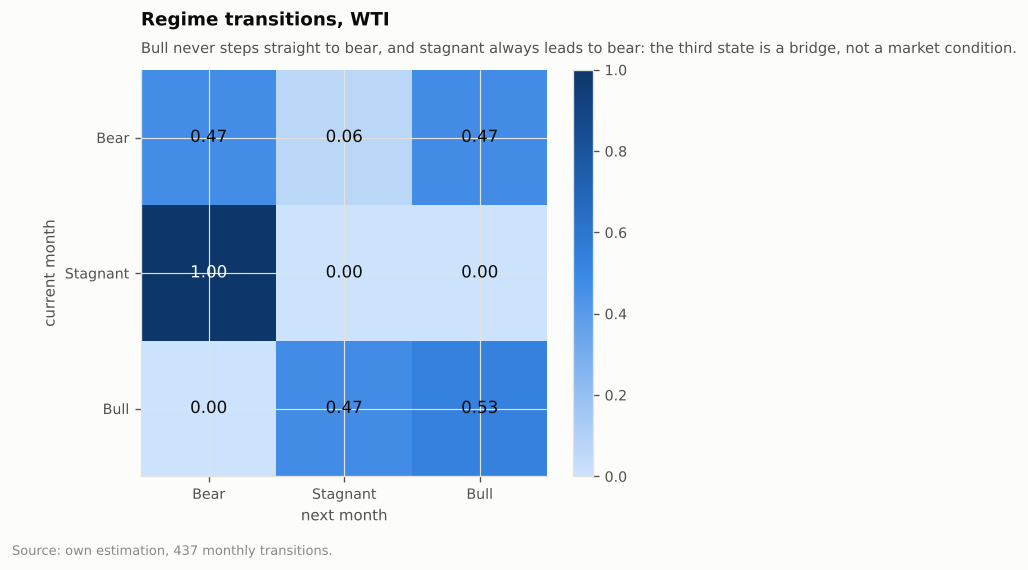

In [ ]:
print("empirical transition matrix, rows are the current month")
display(tm)
fg.fig_transition(tm); plt.show()

In [ ]:
# cross-check against the hand-coded event flag built in GWP1
geo = monthly["GEOEVENT"]
ev = geo[geo == 1].index
NAME = {0: "bear", 1: "stagnant", 2: "bull"}
mix_ev = disc_s["WTI_M"].loc[disc_s.index.isin(ev)].map(NAME).value_counts(normalize=True)
mix_all = disc_s["WTI_M"].map(NAME).value_counts(normalize=True)
display(pd.DataFrame({"event months": mix_ev, "whole sample": mix_all}).round(3))

,event months,whole sample
WTI_M,,
bear,0.562,0.395
bull,0.250,0.393
stagnant,0.188,0.212


**Answer.** The longest bear run, July 2014 to January 2015, takes WTI from 103.59 to
47.22 and spans the November 2014 OPEC meeting that declined to cut. The next two cover
the Lehman failure and Desert Storm. The longest bull runs follow the 1999 OPEC cut and
the 2016 OPEC+ agreement. Every one of those dates already sits on the event flag built
by hand in GWP1, independently of any model.

Stated as a number: across the sixteen flagged months the decoded regime is bear 56.2
per cent of the time against 39.5 per cent unconditionally. Documented oil shocks skew
the regime distribution, which a purely statistical decoder had no way of knowing.

# Step 7. The latent meaning of each hidden state

Ranking by mean change names the states. Whether the names describe anything is a
separate question, and the transition matrix answers it.

In [ ]:
dur = episodes.groupby("regime")["months"].agg(["mean", "max"]).round(2)
display(dur)
print("\nno stagnant episode anywhere in the sample lasts more than",
      int(episodes[episodes.regime == 'stagnant'].months.max()), "month")

,mean,max
regime,,
bear,1.86,7
bull,2.12,6
stagnant,1.00,1



no stagnant episode anywhere in the sample lasts more than 1 month


**Answer.** Bear and bull carry economic content: mean duration 1.86 and 2.12 months,
mean move -6.9 and +8.6 per cent, and episodes that match dated events.

The third state does not. Every stagnant episode lasts exactly one month, the chain
never moves from bull straight to bear, and it always leaves stagnant for bear. The
state is the one-month bridge the model is forced to build because it has no other route
from a rising regime to a falling one. That is the identifiability problem of Step 1c
made visible: three states against two symbols is one state more than the alphabet can
separate.

A genuine stagnant regime, a stretch of months with small moves in either direction,
cannot be represented at all when the encoding keeps only the sign of the change. GWP3
is where a three-symbol alphabet should be tested.

# Steps 8 and 9. Hill Climb search

## 9a. A minimal working example

Listing 1 of the dissertation does not run on pgmpy 1.x: `BayesianModel` is now
`DiscreteBayesianNetwork`, `K2Score` is the string `"k2"`, `fit` no longer forwards
`prior_type`, and integer columns are read as continuous. Rewritten, with eight
variables drawn independently and two dependencies imposed so the result can be checked
against a known truth.

In [ ]:
dag_mwe, edges_mwe = pl.hill_climb_mwe()
print("generated: A depends on B and C, H depends on G and A")
print("recovered:", edges_mwe)

generated: A depends on B and C, H depends on G and A
recovered: [('A', 'B'), ('A', 'C'), ('A', 'G'), ('C', 'B'), ('H', 'A'), ('H', 'G')]


In [ ]:
dag_blind, edges_blind = pl.hill_climb_blind_spot()
print("same two dependencies imposed modulo 3")
print("recovered:", edges_blind)

same two dependencies imposed modulo 3
recovered: []


**Answer.** The skeleton is recovered: A is joined to B, C and H, and H to G. The
directions are not the generating ones, A to B rather than B to A, which is the
Markov-equivalence point made in GWP1. Observational data identify an equivalence class,
not a causal story.

The second cell is the warning. Impose the same dependencies modulo three and every pair
becomes marginally independent while the triples are not. A greedy single-edge search
scores every first move at zero and returns the empty graph. Hill climbing cannot find a
dependency that no single edge improves, and nothing in its output says so.

## 9b. The network on the oil panel

Expert seed, K2 score, maximum in-degree three. The cap is not decoration: with three
states a node with p parents needs 3^p parent configurations, and an unconstrained run
on this panel produced a node with seventeen parents, whose conditional probability
table needed 10.9 GB.

In [ ]:
print("expert seed edges")
for a, b in g.EXPERT_EDGES:
    print(f"   {a} -> {b}")

res = summary["results"]
for tag in ["causal", "lisse"]:
    r = res[tag]
    label = "causal decoding" if tag == "causal" else "smoothed decoding (annex)"
    print(f"\n{label}: {r['n_edges']} edges")
    print("   Markov blanket of FORECAST:", r["blanket"])

expert seed edges
   CAP_OILGAS -> IP_OILGAS
   IP_DRILL -> CAP_OILGAS
   IP_OILGAS -> WTI_M
   INDPRO -> IGREA
   IGREA -> WTI_M
   GEOEVENT -> WTI_M
   WTI_M -> FORECAST

causal decoding: 16 edges
   Markov blanket of FORECAST: ['WTI_M']

smoothed decoding (annex): 18 edges
   Markov blanket of FORECAST: ['CPIENG', 'INDPRO', 'PPI_OILGAS', 'WTI_M']


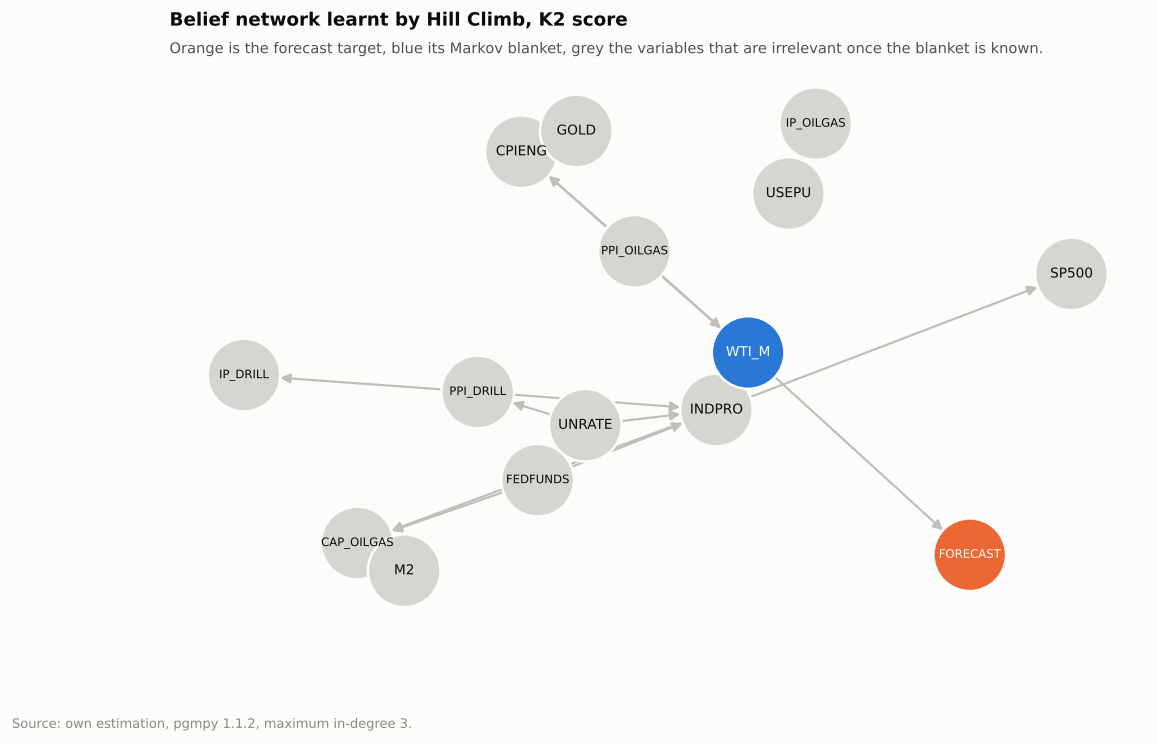

In [ ]:
fg.fig_network(res["causal"]["edges"]); plt.show()

n  network  persistence  majority class  chance
decoding          split                                                  
Causal decoding   valid  41   0.5854       0.5122          0.5854  0.3333
                  test   42   0.4524       0.5238          0.4524  0.3333
Smoothed decoding valid  44   0.7045       0.3636          0.3864  0.3333
                  test   44   0.7273       0.3864          0.4773  0.3333

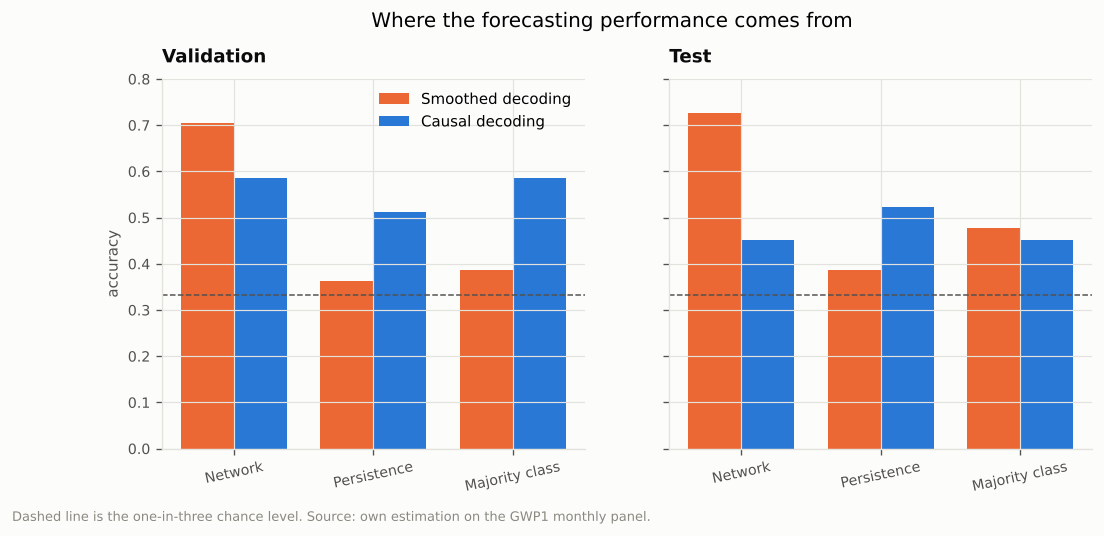

In [ ]:
rows = []
for tag, label in [("causal", "Causal decoding"), ("lisse", "Smoothed decoding")]:
    for split in ["valid", "test"]:
        r = res[tag][split]
        rows.append({"decoding": label, "split": split, "n": r["n"],
                     "network": r["network_accuracy"],
                     "persistence": r["persistence_accuracy"],
                     "majority class": r["majority_accuracy"],
                     "chance": r["chance"]})
display(pd.DataFrame(rows).set_index(["decoding", "split"]))
fg.fig_accuracy(res); plt.show()

**Answer.** Under the causal rule the network reaches 58.5 per cent on validation and
45.2 per cent on test, against a one-in-three chance level. On test that is exactly the
majority-class figure and below the 52.4 per cent of a persistence rule. The network as
specified does not beat predicting that next month looks like this month.

Under the smoothed rule the same pipeline reaches 70.5 and 72.7 per cent. The gap is the
smoothing: 14.5 per cent of labels change between the two decodings on average, 22.2 per
cent on WTI itself, and the Markov blanket of the target collapses from four variables to
one. The annex carries the full comparison.

The expert seed is also informative by what survives. Hill climbing deletes the supply
and demand edges we seeded, IP_OILGAS to WTI and IGREA to WTI, and leaves the event flag
isolated. On the causal encoding the data do not support the economics we assumed, which
is a result about the encoding as much as about the market.

# Annex. The smoothed variant in full

Kept so the contrast is reproducible rather than asserted.

,share of months labelled identically
USEPU,0.754
WTI_M,0.778
GOLD,0.785
INDPRO,0.787
CPIENG,0.807
UNRATE,0.809
PPI_OILGAS,0.812
GS10,0.845
IP_OILGAS,0.845
M2,0.862


mean agreement: 0.855


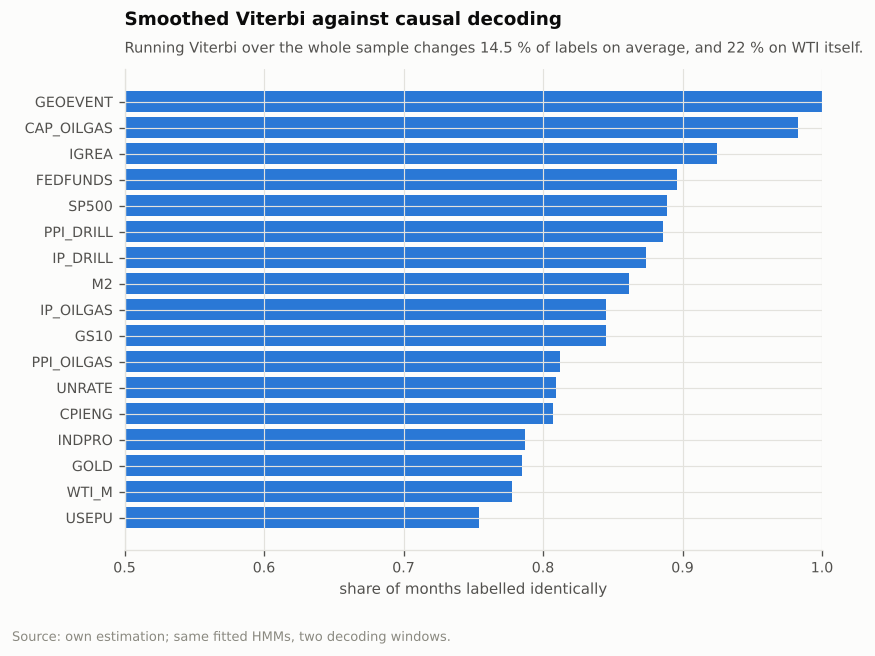

In [ ]:
agree = pd.Series(summary["agreement_smoothed_vs_causal"]).sort_values()
display(agree.to_frame("share of months labelled identically"))
print("mean agreement:", summary["mean_agreement"])
fg.fig_decoding_gap(agree); plt.show()

In [ ]:
print("edges learnt under smoothed decoding")
for a, b in res["lisse"]["edges"]:
    print(f"   {a} -> {b}")

edges learnt under smoothed decoding
   CPIENG -> PPI_OILGAS
   FEDFUNDS -> IP_DRILL
   INDPRO -> UNRATE
   INDPRO -> CAP_OILGAS
   INDPRO -> PPI_DRILL
   INDPRO -> SP500
   INDPRO -> CPIENG
   UNRATE -> PPI_DRILL
   UNRATE -> FEDFUNDS
   GEOEVENT -> SP500
   GEOEVENT -> USEPU
   PPI_DRILL -> SP500
   GOLD -> PPI_DRILL
   WTI_M -> CPIENG
   WTI_M -> PPI_OILGAS
   FORECAST -> PPI_OILGAS
   FORECAST -> CPIENG
   FORECAST -> WTI_M


In [ ]:
import json, os
from google.colab import _message, files

NOM = "GWP2_Oil_Price_PGM_Code"

nb = _message.blocking_request("get_ipynb", request="", timeout_sec=300)["ipynb"]
with open(f"{NOM}.ipynb", "w", encoding="utf-8") as f:
    json.dump(nb, f)

!jupyter nbconvert --to html --embed-images "{NOM}.ipynb"

print("taille HTML :", round(os.path.getsize(f"{NOM}.html")/1024/1024, 1), "Mo")
files.download(f"{NOM}.html")
files.download(f"{NOM}.ipynb")